# Bring your own clustering

> **New to mdCIF?** Run [1_basic](../1_basic/1_basic.ipynb) first. It explains each step (PCA,
> clustering, medoids, modes) and what ends up in the file. This notebook changes only the
> clustering step.

mdCIF does not care *how* the frames were grouped into states. All it needs is **one label per
frame**: frames with the same number belong to the same state, and `-1` marks a frame that
belongs to no state (noise). Everything after that is the same as in 1_basic: one medoid per state, the
state's population and precision, its own modes, and the file.

Your clustering can come in one of two ways:

| Your clustering is… | Pass it as | What the file records about it |
|---|---|---|
| a scikit-learn-style estimator (anything with a `fit_predict` method) | `cluster(traj, estimator)` | its name, the parameters you changed and the software version, all automatically |
| labels made anywhere else: your own script, cpptraj, GROMACS, a Markov state model… | `cluster(traj, labels=...)` | the method and software you name |

We try one of each on the GB1 run from 1_basic and write two mdCIF files. Everything this notebook
writes goes into this folder:

| File | What |
|---|---|
| `gb1_gmm.cif` | states from a Gaussian mixture (way 1) |
| `labels_rmsd.txt` | our own labels, one per frame (way 2) |
| `gb1_rmsd.cif` | states from those labels |
| `figures/` | Fig. 1 (vector PDF + 600-dpi PNG) |

It runs in under a minute; the trajectory (2 GB) is read once.

In [1]:
import os
import sys

os.environ.setdefault("OMP_NUM_THREADS", "4")  # be polite to shared nodes (set before numpy)
# Use only this environment's packages, even if a module system (e.g. Amber's) put another
# Python's site-packages on PYTHONPATH.
sys.path = [p for p in sys.path if "site-packages" not in p or p.startswith(sys.prefix)]

In [2]:
import textwrap
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import mdcif
from mdcif.pipeline import cluster, load_trajectory, save_mdcif
from mdcif.provenance import load_provenance
from mdcif.reader import read_mdcif
from mdcif.validate import validate_mdcif

warnings.filterwarnings("ignore", category=DeprecationWarning)  # MDAnalysis reader notices

DATA = Path("../../data/3gb1/meld")      # the GB1 MELD run of 1_basic, not in git
TOP = DATA / "3gb1_HMR.prmtop"           # Amber topology
TRAJ = DATA / "meld.nc.001"              # replica 1: 300 K
FIGS = Path("figures")                   # Fig. 1 goes here
FIGS.mkdir(exist_ok=True)
print("mdcif", mdcif.__version__)

traj = load_trajectory(TOP, TRAJ, start=25_000, step=10)   # as in 1_basic: read, superpose, PCA
print(f"{traj.n_frames} frames from 50 ns on; each one is now a point on PCs 1-3")

mdcif 0.0.1


17683 frames from 50 ns on; each one is now a point on PCs 1-3


## 1. A scikit-learn-style estimator

Any object with a `fit_predict` method works, whether one of scikit-learn's clustering classes
or a class of your own. `cluster` gives it each frame's position on PCs 1–3 (`n_pcs=` changes
how many PCs; `features="cartesian"` gives it the superposed Cα coordinates instead).

Our example is a **Gaussian mixture**, which describes the map as a few overlapping bell-shaped
clouds. You choose how many (3 here), and every frame goes to its most likely cloud, so, unlike
HDBSCAN, it leaves no frame as noise.

In [3]:
from sklearn.mixture import GaussianMixture

gmm = cluster(traj, GaussianMixture(n_components=3, random_state=0))
print(gmm.details)
for c, f in enumerate(gmm.representatives):
    print(f"state {c + 1}: {gmm.populations[c]:6d} frames "
          f"({100 * gmm.populations[c] / traj.n_frames:4.1f}%), medoid {traj.frame_label(f)}, "
          f"precision {gmm.precision[c]:.2f} Å")

GaussianMixture on PCA projection (global PCs 1-3), n_components 3, random_state 0
state 1:   9378 frames (53.0%), medoid frame 200200, t = 400.402 ns, precision 1.72 Å
state 2:   7469 frames (42.2%), medoid frame 171630, t = 343.262 ns, precision 1.07 Å
state 3:    836 frames ( 4.7%), medoid frame 127120, t = 254.242 ns, precision 0.93 Å


The states are numbered by size, so state 1 is the most populated and becomes model 1 in the
file. Saving works as in 1_basic.

In [4]:
summary = save_mdcif("gb1_gmm.cif", traj, gmm, load_provenance("provenance.yaml"),
                     reference="3GB1")
print(summary.report())
validate_mdcif("gb1_gmm.cif")   # raises with the list of problems if anything is wrong
print("valid")

gb1_gmm.cif: 17683 frames, 56 analysis atoms, 435 deposited atoms
  global PCA var% 60/11/8 (cum 79%)
  clustering: GaussianMixture on PCA projection (global PCs 1-3), n_components 3, random_state 0, 3 clusters
  model 1:  9378 frames (53.0%), medoid frame 200200, t = 400.402 ns, precision 1.72 A, RMSD to PDB 3GB1 model 1 2.54 A, modes var% 31/13/9 (cum 53%)
  model 2:  7469 frames (42.2%), medoid frame 171630, t = 343.262 ns, precision 1.07 A, RMSD to PDB 3GB1 model 1 3.06 A, modes var% 23/13/8 (cum 43%)
  model 3:   836 frames ( 4.7%), medoid frame 127120, t = 254.242 ns, precision 0.93 A, RMSD to PDB 3GB1 model 1 9.04 A, modes var% 20/14/9 (cum 43%)
  timings: modes 0.5s, reference 0.2s, write 0.1s


valid


## 2. Your own labels

Labels can come from anywhere: the per-frame cluster numbers written by cpptraj or GROMACS, the
discrete trajectory of a Markov state model, or a few lines of your own code. They follow two rules:

1. **One integer per analysed frame, in order.** Here that means the 17,683 frames read with
   `start=25_000, step=10`. If your tool labelled every saved frame, take the same slice:
   `all_labels[25_000::10]`.
2. **`-1` = noise.** The frame belongs to no state and is left out of every model. The other
   numbers are only names: mdCIF renumbers the states by size.

As an example, here is a rule a folding study might use: the Cα RMSD of each frame to the NMR
structure (3GB1 model 1). Below 5 Å the protein is folded, above 8 Å it is in the misfolded
state of 1_basic (its model 2), and the few frames in between are on their way from one to the
other, so they count as noise.

In [5]:
import gemmi

from mdcif.reference import load_reference
from mdcif.trajectory import superpose

nmr = gemmi.read_structure(str(load_reference("3GB1").path))   # downloaded once, then cached
nmr_ca = np.array([[a.pos.x, a.pos.y, a.pos.z] for res in nmr[0][0] for a in res
                   if a.name == "CA"])
fitted = superpose(traj.raw, nmr_ca)[0]                        # every frame onto the NMR Cα
rmsd = np.sqrt(((fitted - nmr_ca) ** 2).sum(axis=2).mean(axis=1))

labels = np.full(traj.n_frames, -1)      # noise, unless a rule below says otherwise
labels[rmsd < 5] = 0                     # folded
labels[rmsd > 8] = 1                     # misfolded
np.savetxt("labels_rmsd.txt", labels, fmt="%d")   # one per line: what mdcif build --labels reads
print(f"folded {np.mean(labels == 0):.1%}, misfolded {np.mean(labels == 1):.1%}, "
      f"noise {np.sum(labels == -1)} frames")

folded 95.2%, misfolded 4.7%, noise 6 frames


Next, name your method, so that readers of the file know where the states came from. Here
`method` and `software` come from the `clustering:` block of [`provenance.yaml`](provenance.yaml),
which `mdcif build --labels` reads too; you can also type them in directly.
`features="cartesian"` records that the labels were computed from coordinates (an RMSD), not
from the PCs.

In [6]:
prov = load_provenance("provenance.yaml")
print("method:  ", prov.clustering.method)
print("software:", prov.clustering.software)
print()

rule = cluster(traj, labels=labels, features="cartesian",
               method=prov.clustering.method, software=prov.clustering.software)
summary = save_mdcif("gb1_rmsd.cif", traj, rule, prov, reference="3GB1")
print(summary.report())
validate_mdcif("gb1_rmsd.cif")
print("valid")

method:   CA RMSD to 3GB1 model 1 (folded < 5 A, misfolded > 8 A)
software: numpy



gb1_rmsd.cif: 17683 frames, 56 analysis atoms, 435 deposited atoms
  global PCA var% 60/11/8 (cum 79%)
  clustering: CA RMSD to 3GB1 model 1 (folded < 5 A, misfolded > 8 A) on aligned Cartesian coordinates, 2 clusters, noise 0.0%
  model 1: 16841 frames (95.2%), medoid frame 142700, t = 285.402 ns, precision 1.61 A, RMSD to PDB 3GB1 model 1 2.61 A, modes var% 27/20/8 (cum 54%)
  model 2:   836 frames ( 4.7%), medoid frame 127120, t = 254.242 ns, precision 0.93 A, RMSD to PDB 3GB1 model 1 9.04 A, modes var% 20/14/9 (cum 43%)
  timings: modes 0.5s, reference 0.2s, write 0.1s


valid


<div class="alert alert-block alert-info">
    <b><span style="color:red;">Note :</span></b> <code>save_mdcif</code> never reads <code>Clustering:</code> section in the <a href='provenance.yaml'><i>provenance.yaml</i></a>. It takes cluster information from the <code>ClusterResults</code> dataclass instance. For section 1, this is <code>gmm</code>. For section 2, we used instance <code>rule</code> that we custom built with data read from the existing <a href='provenance.yaml'><i>provenance.yaml</i></a>.
</div>


## 3. The two files side by side

Read back with `read_mdcif`, each file says how its states were made (the clustering step in
`ihm_modeling_post_process`, with its `software`) and keeps the map to draw them on
(`_mdcif_projection`).

In [7]:
data = {name: read_mdcif(name) for name in ("gb1_gmm.cif", "gb1_rmsd.cif")}
for name, d in data.items():
    step = d.system.ensembles[0].post_process          # the clustering step
    sw = step.software
    print(f"{name}: {len(d.system.ensembles)} models, "
          f"{Path(name).stat().st_size / 1024:.0f} KB")
    print(textwrap.fill(f"how: {step.details}", 96, initial_indent="  ",
                        subsequent_indent="       "))
    print("  software:", " ".join(x for x in (sw.name, sw.version) if x), "\n")

gb1_gmm.cif: 3 models, 315 KB
  how: GaussianMixture on PCA projection (global PCs 1-3), n_components 3, random_state 0;
       replica 1 (300 K), 50-403.65 ns, every 10th saved frame (20 ps)
  software: sklearn 1.9.1 

gb1_rmsd.cif: 2 models, 280 KB
  how: CA RMSD to 3GB1 model 1 (folded < 5 A, misfolded > 8 A) on aligned Cartesian coordinates;
       replica 1 (300 K), 50-403.65 ns, every 10th saved frame (20 ps); 0.0% of frames in no
       cluster (noise)
  software: numpy 



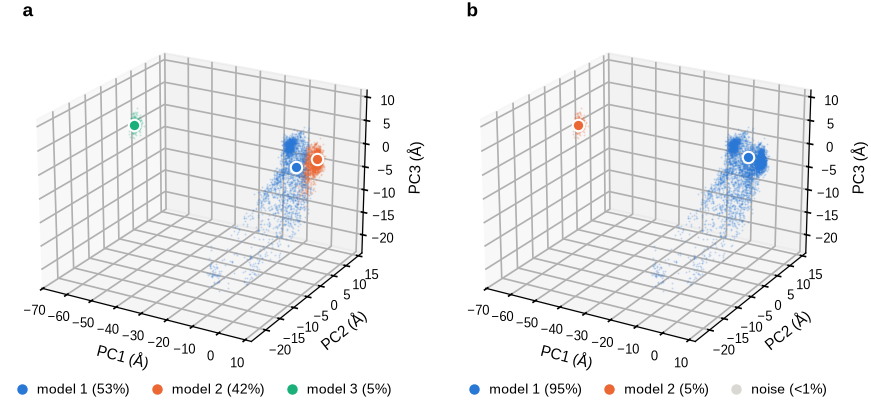

In [8]:
from matplotlib.lines import Line2D

from mdcif.plot import model_projections

STATE = ["#2a78d6", "#eb6834", "#1baf7a"]   # model 1, 2, 3 (colour-blind-safe, as in 1_basic)
NOISE = "#d9d8d3"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.labelsize": 7, "legend.fontsize": 6.5, "xtick.labelsize": 6,
    "ytick.labelsize": 6, "axes.linewidth": 0.6, "legend.frameon": False, "figure.dpi": 150,
    "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42,
})

fig = plt.figure(figsize=(7.0, 3.4))                   # journal double column
for k, d in enumerate(data.values()):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d", computed_zorder=False)
    p = d.projection                                   # the frames stored in the file
    medoids = model_projections(d)                     # each model placed on the same PCs
    handles = []
    for m in [0, *sorted(medoids, reverse=True)]:      # noise first, model 1 on top
        sel = p["model_id"] == m
        if sel.any():
            color = NOISE if m == 0 else STATE[(m - 1) % 3]
            ax.scatter(*p["coords"][sel].T, s=0.8, lw=0, alpha=0.25, color=color,
                       depthshade=False, rasterized=True)
            name = "noise" if m == 0 else f"model {m}"
            share = f"{100 * sel.mean():.0f}%" if sel.mean() >= 0.01 else "<1%"
            handles.append(Line2D([], [], ls="", marker="o", ms=4, color=color,
                                  label=f"{name} ({share})"))
    for m, xyz in medoids.items():
        ax.scatter(*xyz[:3], s=30, color=STATE[(m - 1) % 3], edgecolors="white",
                   linewidths=1.0, depthshade=False)
    ax.set_xlabel("PC1 (Å)", labelpad=-6)
    ax.set_ylabel("PC2 (Å)", labelpad=-6)
    ax.set_zlabel("PC3 (Å)", labelpad=-6)
    ax.tick_params(pad=-2)
    ax.view_init(elev=22, azim=-60)
    ax.legend(handles=handles[::-1], loc="upper center", bbox_to_anchor=(0.5, 0.02),
              ncol=len(handles), handletextpad=0.1, columnspacing=1.0)
    ax.text2D(0.02, 0.98, "ab"[k], transform=ax.transAxes, fontsize=9, fontweight="bold")
for ext in ("pdf", "png"):
    fig.savefig(FIGS / f"fig1_two_clusterings.{ext}")
plt.show()

**Figure 1.** The same 5,000 stored frames on PCs 1–3, coloured by state: **a**, Gaussian
mixture (`gb1_gmm.cif`); **b**, the RMSD rule (`gb1_rmsd.cif`). Large dots: the models (medoids).
Drawn from the two files alone.

The Gaussian mixture splits the folded basin into two states of about the same size (models 1
and 2, medoids 2.5 and 3.1 Å from 3GB1) and keeps the misfolded state apart (model 3). The RMSD
rule sees only folded and misfolded: the same two states HDBSCAN finds in 1_basic, with the six
noise frames taken out of model 1. Which split is right depends on the question you are asking
(substates of the folded protein, or folded versus misfolded); either way, the file records how
its states were made.

## The same from the command line

`mdcif build` takes labels from a file (`.npy`, or text with one integer per line):

```bash
mdcif build ../../data/3gb1/meld/3gb1_HMR.prmtop ../../data/3gb1/meld/meld.nc.001 \
    --provenance provenance.yaml --start 25000 --step 10 \
    --labels labels_rmsd.txt --output gb1_rmsd.cif
```

The method and software come from the `clustering:` block of the YAML, and `--labels-method`
overrides the method. Estimators are Python-only. [3_cli](../3_cli/3_cli.ipynb) covers the
command line in full.